# MU281 Directed GFS: prescribed SIP demo

This focused notebook uses the cleaned MU284 population (281 units), sample size 4, a reproducibly permuted target, and a single Directed-GFS run.

The target walk makes exactly 10,000 exchange *attempts*. Non-moving proposals are retained as attempts but do not contribute to the accepted-exchange count.


In [8]:
# ---------------- USER SETTINGS ----------------

POPULATION = "MU284"       # The CSV has 281 usable rows after the three documented outliers.
N = 281
n = 40
FIP_TYPE = "unequal"
SEED = 12345
MU284_SIZE_COLUMN = "P75"

# Target: standard fixed-size GFS design in a reproducibly permuted order.
TARGET_ATTEMPTS = 10_000   # Every proposal counts, whether or not it changes the distribution.
TARGET_ALPHA = 0.75
TARGET_M = 1
TARGET_CHECK_EVERY = 1_000

# Retained only because the notebook defines the original-search helper; it is never run here.
GFS_MAX_EVALUATIONS = 20_000
GFS_FRONTIER_SIZE = 50
GFS_EXCHANGE_COEFFICIENT = 0.75
GFS_M = 1
GFS_EXCHANGE_NODES = 10
GFS_ORDER_NODES = 2
GFS_STAGNATION_EVALUATIONS = None
GFS_RMSE_STOP = 1e-10
GFS_AUTO_RESTART = False
GFS_RESTART_EXCHANGES = 3
GFS_MAX_EMPTY_RESTARTS = 3

# The only reconstruction method executed by this notebook.
RUN_GFS_DIRECTED = True
N_REPETITIONS = 1
DIRECTED_N_JOBS = 1
DIRECTED_RMSE_STOP = 1e-10
DIRECTED_MAX_EVALUATIONS = 100_000
DIRECTED_BATCH_SIZE = 100
DIRECTED_SAVE_RESULTS = True

# All other reconstruction methods are disabled.
RUN_CP2 = False
RUN_DSD = False
RUN_EXACT_QP = False
CP2_MAX_EVALUATIONS = 50_000
CP2_MAX_SECONDS = 60
DSD_MAX_EVALUATIONS = 1_000
EXACT_MAX_SECONDS = 60
ENUMERATION_LIMIT = 50_000

RHO_BOUNDARY_TOL = 1e-12
TRACE_EVERY = 1_000
PROGRESS_EVERY = 1_000
SHOW_FULL_SUPPORT = False
BENCHMARK_EVALUATIONS = 100
ALLOW_LONG_RUN = True

# ------------------------------------------------


## 1. Imports and the precision adapter

We import your actual `Population`, `Order`, and `GreedyBestFirstSearch` classes.
The existing small `Float64Design` adapter retains `Design._build`, `Design.exchange`,
and `Design._switch`; it keeps probability extraction in double precision, retains
fragments above $10^{-15}$ instead of $10^{-9}$, preserves its type when copying,
and conditions certainty units out of the original builder before adding them back.
It is a numerical adapter, not a different search algorithm.

`seeded_package` temporarily seeds package-created random generators and restores
random state afterwards. This notebook is serial, so no multiprocessing is involved.
You can inspect the adapter at `prescribed_sip/methods/package_gfs.py`.

In [9]:
import sys
from pathlib import Path
from itertools import combinations
from math import comb, fsum
from time import perf_counter
import inspect

# Works from the repository root or this notebook's directory.
REPO = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "graphical_sampling").is_dir()), None)
if REPO is None:
    raise RuntimeError("Open this notebook inside the graphical-sampling repository.")
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from IPython.display import display
from graphical_sampling import Population, Order, Design
from graphical_sampling.order import Cluster, Zone
from graphical_sampling.search import GreedyBestFirstSearch
from prescribed_sip.methods.package_gfs import Float64Design, seeded_package, extract_support

plt.rcParams.update({"figure.figsize": (7, 3.5), "axes.grid": False})
print("Repository:", REPO)
print("Python:", sys.executable)
print("Search source:", inspect.getsourcefile(GreedyBestFirstSearch.run))
print("Exchange source:", inspect.getsourcefile(Float64Design.exchange))
assert Float64Design.exchange is Design.exchange
assert Float64Design._switch is Design._switch
print("Confirmed: adapter uses the actual package exchange and four-sample split.")


Repository: /home/bardia/projects/graphical-sampling
Python: /home/bardia/projects/graphical-sampling/.venv/bin/python
Search source: /home/bardia/projects/graphical-sampling/graphical_sampling/search/gbfs.py
Exchange source: /home/bardia/projects/graphical-sampling/graphical_sampling/design.py
Confirmed: adapter uses the actual package exchange and four-sample split.


## 2. Construct the population and prescribed FIP

For positive sizes $x_i$, start with $\pi_i=nx_i/\sum_jx_j$. If this exceeds one,
solve $\sum_i\min(cx_i,1)=n$ by bisection. Certainty units have $\pi_i=1$.
Synthetic units sit in their original order on a line; no geography is invented.

**MU284 data detail:** the CSV in this repository has **281 observations**. We use
all actual rows and report `N` accordingly. Set `POPULATION="synthetic"` to obtain
exactly 284 units. `P75` is used for size in
`simulations/abc/scripts/run_abc_mu284_terminal.py`; other historical examples used
other columns, so the choice is explicit and editable.

Loaded /home/bardia/projects/graphical-sampling/simulations/abc/populations/real/MU284.csv: 281 actual rows (requested N=281).
Size column: P75
N=281, n=40, min(pi)=0.02346729, max(pi)=0.80962159, mean(pi)=0.14234875, sum(pi)=40.000000000000


,unit (0-based),x,pi
0,0,27.0,0.158404
1,1,15.0,0.088002
2,2,20.0,0.117336
3,3,15.0,0.088002
4,4,52.0,0.305075
...,...,...,...
276,276,64.0,0.375477
277,277,35.0,0.205339
278,278,27.0,0.158404
279,279,9.0,0.052801


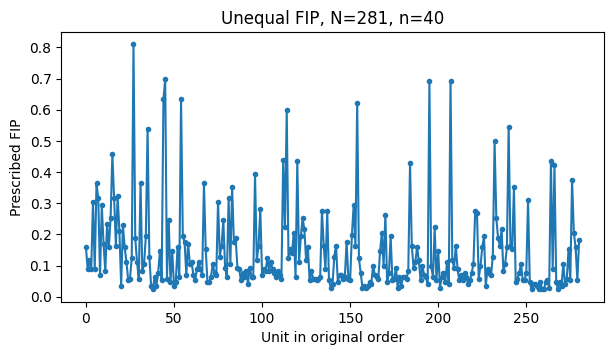

In [10]:
def inclusion_probabilities(x, sample_size):
    x = np.asarray(x, dtype=np.float64)
    if np.any(~np.isfinite(x)) or np.any(x <= 0):
        raise ValueError("Size values must be finite and positive.")
    if not 1 <= sample_size <= len(x):
        raise ValueError("Require 1 <= n <= N.")
    direct = sample_size * x / x.sum()
    if np.max(direct) <= 1:
        return direct
    lower, upper = 0., 1. / float(np.min(x))
    for _ in range(100):
        c = (lower + upper) / 2
        if np.minimum(c * x, 1.).sum() < sample_size:
            lower = c
        else:
            upper = c
    return np.minimum(((lower + upper) / 2) * x, 1.)

rng = np.random.default_rng(SEED)
if POPULATION == "MU284":
    dataset_path = REPO / "simulations/abc/populations/real/MU284.csv"
    population_df = pd.read_csv(dataset_path)
    requested_N = N
    N = len(population_df)
    x = population_df[MU284_SIZE_COLUMN].to_numpy(dtype=np.float64)
    print(f"Loaded {dataset_path}: {N} actual rows (requested N={requested_N}).")
    print("Size column:", MU284_SIZE_COLUMN)
elif POPULATION == "synthetic":
    x = rng.uniform(0.65, 1.35, N).astype(np.float64)
    population_df = pd.DataFrame({"unit": np.arange(N), "x": x})
else:
    raise ValueError('POPULATION must be "synthetic" or "MU284".')

if not isinstance(n, int) or not 1 <= n <= N:
    raise ValueError("n must be an integer between 1 and the actual population size.")
if FIP_TYPE == "equal":
    pi = np.full(N, n / N, dtype=np.float64)
elif FIP_TYPE == "unequal":
    pi = inclusion_probabilities(x, n)
else:
    raise ValueError('FIP_TYPE must be "equal" or "unequal".')
coords = np.column_stack([np.linspace(0., 1., N), np.zeros(N)])
pair_indices = np.triu_indices(N, 1)
number_of_pairs = comb(N, 2)
assert abs(pi.sum() - n) < 1e-10
print(f"N={N}, n={n}, min(pi)={pi.min():.8f}, max(pi)={pi.max():.8f}, "
      f"mean(pi)={pi.mean():.8f}, sum(pi)={pi.sum():.12f}")
display(pd.DataFrame({"unit (0-based)": np.arange(N), "x": x, "pi": pi}))
plt.plot(np.arange(N), pi, ".-")
plt.xlabel("Unit in original order"); plt.ylabel("Prescribed FIP")
plt.title(f"{FIP_TYPE.capitalize()} FIP, N={N}, n={n}"); plt.show()


## 3. Small, visible probability and SIP helpers

If $p(s)$ is the probability of sample $s$, then
$\pi_i=\sum_s p(s)I_i(s)$ and $\pi_{ij}=\sum_s p(s)I_i(s)I_j(s)$.
`compute_SIP` implements this formula with a sparse indicator matrix, using only
the **current support**, not all $\binom{N}{n}$ possible samples. It therefore works
at 284 units too. The diagonal of the matrix is FIP.

`validate_design` independently recomputes these sums sample by sample. Nothing is
renormalized to conceal mass or FIP error. Standardized dependence is computed
only for pairs without certainty units; their zero-variance correlation is undefined.

In [11]:
from prescribed_sip.core.dependence import DependenceError
rho_profile = DependenceError(pi, boundary_tol=RHO_BOUNDARY_TOL)

def distribution(design):
    """Aggregate duplicate sample fragments without altering the design."""
    if hasattr(design, "mass"):   # Enumerated competitors return a Support object.
        return dict(design.mass)
    fragments = {}
    for heap in design._heaps:
        # _MaxHeap stores negated probabilities; read without allocating _Sample copies.
        for stored in heap.heap:
            fragments.setdefault(stored.ids, []).append(-float(stored.prob))
    # Immutable ID sets group duplicates; sort each unique sample only once.
    return {tuple(sorted(ids)): fsum(parts) for ids, parts in fragments.items()}


def compute_SIP(design, unit_order=None):
    """Read SIP in original ID order, or in the explicitly requested ID sequence."""
    mass = distribution(design)
    size = design.pop.N if hasattr(design, "pop") else design.N
    samples = list(mass)
    probabilities = np.array(list(mass.values()), dtype=np.float64)
    row = np.array([i for sample in samples for i in sample], dtype=int)
    if unit_order is not None:
        unit_order = np.asarray(unit_order)
        if (unit_order.shape != (size,) or not np.issubdtype(unit_order.dtype, np.integer)
                or not np.array_equal(np.sort(unit_order), np.arange(size))):
            raise ValueError("unit_order must contain each original unit ID exactly once.")
        position_for_id = np.empty(size, dtype=int)
        position_for_id[unit_order] = np.arange(size)
        row = position_for_id[row]
    col = np.repeat(np.arange(len(samples)), [len(s) for s in samples])
    indicators = sparse.csr_matrix((np.ones(len(row)), (row, col)),
                                   shape=(size, len(samples)))
    return (indicators.multiply(probabilities) @ indicators.T).toarray()


def entropy(design):
    p = np.array(list(distribution(design).values()), dtype=np.float64)
    p = p[p > 0]
    return float(-np.sum(p * np.log(p)))   # Natural logarithms: entropy in nats.


def validate_design(design, expected_pi):
    size, sample_size = len(expected_pi), int(round(sum(expected_pi)))
    mass = distribution(design)
    independent = np.zeros((size, size), dtype=np.float64)
    for sample, probability in mass.items():
        if probability > 0 and len(sample) != sample_size:
            raise ValueError("A positive-probability sample has the wrong size.")
        independent[np.ix_(sample, sample)] += probability
    computed = compute_SIP(design)
    errors = {"FIP max error": float(np.max(abs(np.diag(independent) - expected_pi))),
              "Probability sum error": abs(fsum(mass.values()) - 1.),
              "Min probability": min(mass.values()),
              "SIP recomputation error": float(np.max(abs(computed - independent))),
              "Fixed-size row error": float(np.max(abs(independent.sum(axis=1)
                                                       - sample_size * expected_pi))),
              "Pair-total error": abs(independent[np.triu_indices(size, 1)].sum()
                                       - comb(sample_size, 2))}
    if errors["Min probability"] < -1e-12 or any(
        value > 1e-9 for name, value in errors.items() if name != "Min probability"
    ):
        raise ValueError(f"Design validation failed: {errors}")
    return errors


def sip_errors(Pi, target):
    difference = (Pi - target)[np.triu_indices(len(Pi), 1)]
    D2 = float(difference @ difference)
    return {"D2": D2, "RMSE": float(np.sqrt(D2 / len(difference))),
            "Max SIP error": float(np.max(abs(difference)))}


def dependence_distance(Pi, reference):
    return rho_profile.from_matrices(Pi, reference)


def enumeration_allowed(size, sample_size):
    return size < 100 and comb(size, sample_size) <= ENUMERATION_LIMIT


def show_support(design, label):
    print(f"{label}: support={len(distribution(design))}, entropy={entropy(design):.8f}")
    if SHOW_FULL_SUPPORT and N <= 12:
        with pd.option_context("display.max_rows", None):
            display(pd.DataFrame([{"sample (0-based)": sample, "probability": p}
                                   for sample, p in sorted(distribution(design).items())]))


## 4. Build the original simple GFS design

One cluster, one zone, original unit order, and one unsplit segment per unit.
The build below uses the package's order representation and design builder.
Setting `pop._n` avoids truncating a floating sum such as 3.9999999999999996 to 3.

In [12]:
pop = Population(coords=coords, inclusions=pi, variable=x, n=None)
pop._n = n
zone = Zone(_shares=np.ones(N), _indices=np.arange(N), sort=list(range(N)))
order = Order(pop)
order.clusters = [Cluster(label=0, zones=[zone])]
order.num_zones = 1
order.num_splits = 1
order._build_order(1)
with seeded_package(SEED):
    p0 = Float64Design.from_order(pop, order)
Pi0 = compute_SIP(p0)
show_support(p0, "p0")
print("Independent initial checks:", validate_design(p0, pi))


p0: support=276, entropy=5.25495420
Independent initial checks: {'FIP max error': 2.120525977034049e-14, 'Probability sum error': 2.0095036745715333e-14, 'Min probability': 0.0002933411557535237, 'SIP recomputation error': 0.0, 'Fixed-size row error': 8.455458555545192e-13, 'Pair-total error': np.float64(1.5688783605583012e-11)}


## 5. Create a target using random package segment exchanges

There is **no reconstruction criterion in this cell**. In a package exchange,
two samples $a,b$ trade one unit each: $a',b'$. Mass
$\epsilon=\alpha\min[p(a),p(b)]$ is removed from $a,b$ and added to $a',b'$.
The sum of the two indicator vectors is unchanged, so FIP and sample size are
preserved. We call your actual `Design.exchange`, with random fragment selection.

We count **accepted exchanges that change the aggregated sample distribution**
(total mass movement $>10^{-14}$). Identical fragments or a swap that just exchanges
sample labels do not count. This convention differs from the earlier paper walk,
which included valid null transactions. `TARGET_M` requests partitions; only one
partition exists here, so its effective value is one.

The target here is the **endpoint after exactly TARGET_EXCHANGES accepted moves**.
It is not automatically replaced by the most separated snapshot. Inspect the
plots and change the setting yourself. If no nontrivial exchanges are possible,
the cell explains the issue rather than looping forever.

Target construction first draws a reproducible permutation from `SEED` and builds a separate standard fixed-size GFS design in that order. The package `Order` stores original unit IDs, so each prescribed $\pi_i$, coordinate and size value remains attached to its original unit. Random `Design.exchange` operations start from `target_initial`; `p0` is reserved for reconstruction in the original order. Matrix readout in permuted order is restored using `argsort(target_permutation)` before any method sees `Pi_star`. The random walk's distance-from-p0 diagnostics compare original unit IDs at every checkpoint, including the permuted initial endpoint.


In [13]:
# p0 stays in ORIGINAL order for every reconstruction method.
# permutation[position] = original unit ID; pi is NEVER reassigned to another unit.
target_permutation = np.random.default_rng(SEED).permutation(N)
target_permutation_inverse = np.argsort(target_permutation)
target_order = Order(pop)
target_order.clusters = [Cluster(label=0, zones=[Zone(
    _shares=np.ones(N), _indices=np.arange(N), sort=target_permutation.tolist())])]
target_order.num_zones = 1
target_order.num_splits = 1
target_order._build_order(1)
with seeded_package(SEED):
    target_initial = Float64Design.from_order(pop, target_order)
Pi_target_initial = compute_SIP(target_initial)  # Default readout uses original IDs.
print("Target permutation (position -> original unit ID, 0-based):", target_permutation.tolist())
print("Target-start checks:", validate_design(target_initial, pi))
print("Reconstruction start: standard GFS p0 in ORIGINAL population order.")


Target permutation (position -> original unit ID, 0-based): [93, 203, 202, 29, 179, 44, 37, 26, 96, 249, 211, 225, 246, 2, 268, 68, 140, 201, 70, 139, 49, 154, 259, 117, 80, 136, 62, 145, 105, 234, 188, 52, 157, 144, 279, 186, 41, 127, 175, 87, 218, 64, 66, 39, 241, 118, 46, 92, 15, 47, 57, 82, 48, 251, 89, 23, 208, 1, 112, 32, 160, 233, 226, 210, 79, 270, 206, 245, 167, 230, 51, 235, 16, 128, 158, 220, 253, 165, 56, 214, 242, 189, 40, 171, 0, 31, 247, 58, 161, 103, 107, 100, 59, 250, 275, 172, 113, 231, 243, 91, 194, 134, 181, 138, 256, 224, 61, 24, 159, 232, 278, 99, 177, 115, 261, 6, 169, 123, 229, 265, 191, 71, 151, 257, 190, 244, 164, 176, 109, 276, 217, 27, 267, 198, 28, 263, 73, 17, 252, 213, 81, 212, 182, 13, 162, 78, 248, 21, 204, 119, 205, 122, 120, 104, 60, 98, 19, 38, 34, 153, 63, 183, 207, 197, 36, 110, 7, 106, 142, 50, 135, 280, 14, 69, 149, 76, 236, 53, 146, 42, 116, 77, 147, 22, 20, 83, 132, 178, 187, 72, 88, 163, 238, 239, 152, 273, 131, 33, 3, 155, 30, 121, 65, 124, 2

In [14]:
if not isinstance(TARGET_ATTEMPTS, int) or TARGET_ATTEMPTS < 0:
    raise ValueError("TARGET_ATTEMPTS must be a nonnegative integer.")
if not 0 < TARGET_ALPHA <= 1 or not isinstance(TARGET_M, int) or TARGET_M < 1:
    raise ValueError("Require 0 < TARGET_ALPHA <= 1 and positive integer TARGET_M.")
if min(TARGET_CHECK_EVERY, PROGRESS_EVERY, TRACE_EVERY) < 1:
    raise ValueError("Diagnostic intervals must be positive.")

current_design = target_initial.copy()
current_mass = distribution(current_design)  # Reused until a proposal changes the distribution.
accepted_exchanges = 0
attempted_exchanges = 0
target_trace = []
target_started = perf_counter()

def target_checkpoint():
    current_Pi = compute_SIP(current_design)
    target_trace.append({"attempts": attempted_exchanges,
                         "exchanges": accepted_exchanges,
                         "entropy": entropy(current_design),
                         "support": len(distribution(current_design)),
                         "effective support": np.exp(entropy(current_design)),
                         "RMSE from p0": sip_errors(current_Pi, Pi0)["RMSE"],
                         "d_rho": dependence_distance(current_Pi, Pi0),
                         "RMSE_rho from p0": dependence_distance(current_Pi, Pi0),
                         "Max SIP error from p0": sip_errors(current_Pi, Pi0)["Max SIP error"],
                         **rho_profile.counts(),
                         "seconds": perf_counter() - target_started})

target_checkpoint()
with seeded_package(SEED + 1):
    for attempted_exchanges in range(1, TARGET_ATTEMPTS + 1):
        proposal = current_design.copy()
        before = current_mass
        proposal.exchange(partitions=TARGET_M, pull_strategy="random",
                          exchange_coef=TARGET_ALPHA)
        proposal.merge_identical()
        after = distribution(proposal)
        moved_mass = fsum(abs(after.get(s, 0.) - before.get(s, 0.))
                          for s in before.keys() | after.keys())
        if moved_mass > 1e-14:
            current_design = proposal
            current_mass = after
            accepted_exchanges += 1
        if attempted_exchanges % TARGET_CHECK_EVERY == 0:
            validate_design(current_design, pi)
            target_checkpoint()
        if attempted_exchanges % PROGRESS_EVERY == 0:
            print(f"Target: {attempted_exchanges}/{TARGET_ATTEMPTS} attempts; "
                  f"{accepted_exchanges} accepted; {perf_counter() - target_started:.1f} s", flush=True)
if target_trace[-1]["attempts"] != attempted_exchanges:
    target_checkpoint()

# The target is frozen at the endpoint after the requested number of attempts.
p_star = current_design
Pi_star_permuted = compute_SIP(p_star, unit_order=target_permutation)
Pi_star = Pi_star_permuted[np.ix_(target_permutation_inverse, target_permutation_inverse)]
original_id_SIP = compute_SIP(p_star)
if np.max(abs(Pi_star - original_id_SIP)) > 1e-12:
    raise ValueError("Target SIP unit-ID reordering disagrees with independent support readout.")
target_checks = validate_design(p_star, pi)
target_fip_error = float(np.max(abs(np.diag(Pi_star) - pi)))
target_fixed_size_ok = all(len(s) == n for s, p in distribution(p_star).items() if p > 0)
if not target_fixed_size_ok or target_fip_error > 1e-9:
    raise ValueError("Target does not preserve the prescribed FIP or fixed sample size.")
print(f"Target confirmed: every positive-probability sample has exactly n={n} units; "
      f"prescribed FIP preserved (max error={target_fip_error:.2e}, tolerance=1e-9).")
target_runtime = perf_counter() - target_started
target_history = pd.DataFrame(target_trace)
print(f"Target created: {accepted_exchanges} accepted from exactly {attempted_exchanges} attempts; "
      f"TARGET_ATTEMPTS={TARGET_ATTEMPTS}; {target_runtime:.2f} s")
print("Independent target checks:", target_checks)
show_support(p_star, "p_star")


Target: 1000/10000 attempts; 998 accepted; 9.6 s
Target: 2000/10000 attempts; 1997 accepted; 38.5 s
Target: 3000/10000 attempts; 2995 accepted; 87.7 s
Target: 4000/10000 attempts; 3995 accepted; 159.4 s
Target: 5000/10000 attempts; 4995 accepted; 256.7 s
Target: 6000/10000 attempts; 5995 accepted; 380.5 s
Target: 7000/10000 attempts; 6995 accepted; 524.7 s
Target: 8000/10000 attempts; 7995 accepted; 696.2 s
Target: 9000/10000 attempts; 8995 accepted; 891.0 s
Target: 10000/10000 attempts; 9995 accepted; 1114.5 s
Target confirmed: every positive-probability sample has exactly n=40 units; prescribed FIP preserved (max error=1.89e-14, tolerance=1e-9).
Target created: 9995 accepted from exactly 10000 attempts; TARGET_ATTEMPTS=10000; 1115.85 s
Independent target checks: {'FIP max error': 1.887379141862766e-14, 'Probability sum error': 2.042810365310288e-14, 'Min probability': 2.9206671548735517e-14, 'SIP recomputation error': 0.0, 'Fixed-size row error': 7.389644451905042e-13, 'Pair-total er

## 6. Inspect how different the target became

Heatmaps include FIP on the diagonal. Differences, histograms, RMSE, and maximum
pair errors use only unordered off-diagonal pairs. A larger exchange count does
not guarantee a monotonically increasing distance from the starting design.

In [15]:
# # Freeze the interrupted target walk as the target for downstream analysis.
# if target_trace[-1]["exchanges"] != accepted_exchanges:
#     target_checkpoint()

# p_star = current_design
# Pi_star_permuted = compute_SIP(p_star, unit_order=target_permutation)
# Pi_star = Pi_star_permuted[
#     np.ix_(target_permutation_inverse, target_permutation_inverse)
# ]

# # Safety checks from the end of the original target-construction cell.
# original_id_SIP = compute_SIP(p_star)
# if np.max(np.abs(Pi_star - original_id_SIP)) > 1e-12:
#     raise ValueError("Target SIP unit-ID reordering disagrees with support readout.")

# target_checks = validate_design(p_star, pi)
# target_fip_error = float(np.max(np.abs(np.diag(Pi_star) - pi)))
# target_fixed_size_ok = all(
#     len(sample) == n
#     for sample, probability in distribution(p_star).items()
#     if probability > 0
# )
# if not target_fixed_size_ok or target_fip_error > 1e-9:
#     raise ValueError("Partial target does not preserve FIP or fixed sample size.")

# target_runtime = perf_counter() - target_started
# target_history = pd.DataFrame(target_trace)

# print(
#     f"Using interrupted target: {accepted_exchanges:,}/{TARGET_EXCHANGES:,} "
#     f"accepted exchanges; support={len(distribution(p_star)):,}"
# )
# print("Target checks:", target_checks)

Dependence pairs: 39340/39340 included; 0 excluded (RHO_BOUNDARY_TOL=1e-12).
Original-order initial vs target: RMSE=0.04697940202; RMSE_rho=0.3586273451
Maximum SIP difference = 0.3785234517
Median SIP difference = 0.0007420370756
d_rho = 0.3586273451
Entropy initial/target = 5.25495420 / 6.09284166
Support initial/target = 276 / 20223


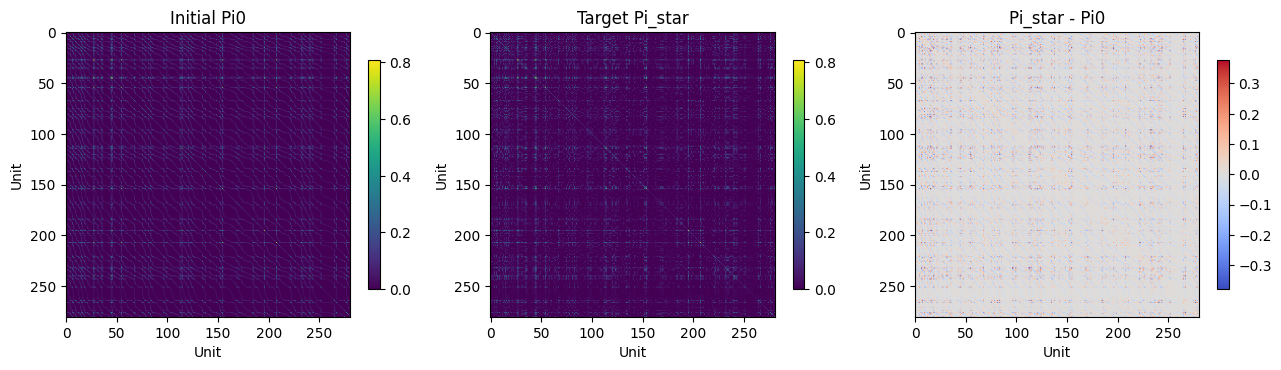

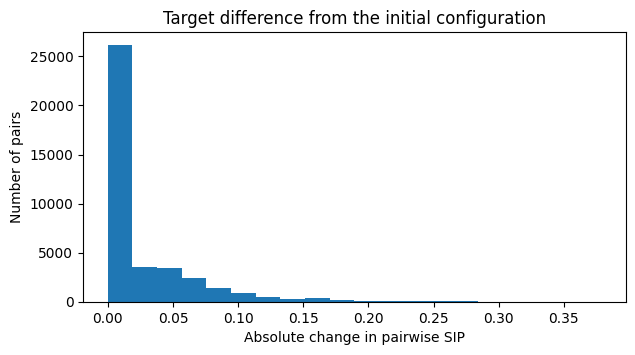

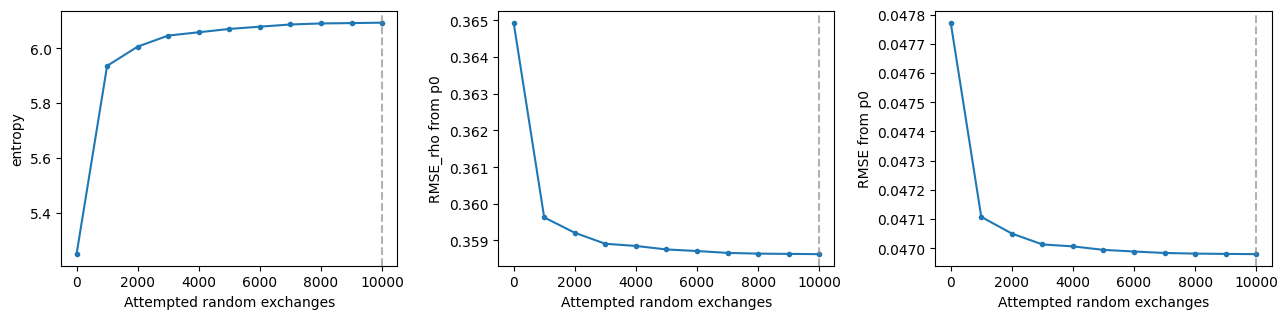

In [16]:
initial_to_target = sip_errors(Pi0, Pi_star)
baseline_rmse = initial_to_target["RMSE"]  # Raw SIP RMSE unchanged.
baseline_rho_error = rho_profile.from_matrices(Pi0, Pi_star)

def comparison_metrics(Pi):
    error = rho_profile.from_matrices(Pi, Pi_star)
    return {"RMSE_rho": error,
            "Recovery_rho": rho_profile.recovery(error, baseline_rho_error),
            **rho_profile.counts()}

print(f"Dependence pairs: {rho_profile.included}/{number_of_pairs} included; "
      f"{rho_profile.excluded} excluded (RHO_BOUNDARY_TOL={RHO_BOUNDARY_TOL:g}).")
if rho_profile.included == 0 or baseline_rho_error == 0:
    print("RMSE_rho is NA if no pairs are valid; Recovery_rho is NA if the initial error is zero/undefined.")

pair_difference = abs((Pi_star - Pi0)[pair_indices])
print(f"Original-order initial vs target: RMSE={baseline_rmse:.10g}; RMSE_rho={baseline_rho_error:.10g}")
print(f"Maximum SIP difference = {pair_difference.max():.10g}")
print(f"Median SIP difference = {np.median(pair_difference):.10g}")
print(f"d_rho = {dependence_distance(Pi_star, Pi0):.10g}")
print(f"Entropy initial/target = {entropy(p0):.8f} / {entropy(p_star):.8f}")
print(f"Support initial/target = {len(distribution(p0))} / {len(distribution(p_star))}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
maximum = max(Pi0.max(), Pi_star.max())
for ax, matrix, label in zip(axes[:2], [Pi0, Pi_star], ["Initial Pi0", "Target Pi_star"]):
    im = ax.imshow(matrix, vmin=0, vmax=maximum, cmap="viridis")
    ax.set_title(label); fig.colorbar(im, ax=ax, shrink=.8)
difference = Pi_star - Pi0
limit = max(float(abs(difference).max()), 1e-15)
im = axes[2].imshow(difference, vmin=-limit, vmax=limit, cmap="coolwarm")
axes[2].set_title("Pi_star - Pi0"); fig.colorbar(im, ax=axes[2], shrink=.8)
for ax in axes:
    ax.set_xlabel("Unit"); ax.set_ylabel("Unit")
plt.tight_layout(); plt.show()

plt.hist(pair_difference, bins=20)
plt.xlabel("Absolute change in pairwise SIP"); plt.ylabel("Number of pairs")
plt.title("Target difference from the initial configuration"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
for ax, column in zip(axes, ["entropy", "RMSE_rho from p0", "RMSE from p0"]):
    ax.plot(target_history["attempts"], target_history[column], ".-")
    ax.set_xlabel("Attempted random exchanges"); ax.set_ylabel(column)
    ax.axvline(TARGET_ATTEMPTS, ls="--", color="grey", alpha=.6)
plt.tight_layout(); plt.show()


## 7. Scoring and observing your existing GFS search

We minimize $D_2=\sum_{i<j}(\pi_{ij}-\pi^*_{ij})^2$, with
$\mathrm{RMSE}=\sqrt{D_2/\binom{N}{2}}$. Candidate scoring recomputes SIP from support.
The optimizer receives `p0`, prescribed FIP, and `Pi_star`; **never `p_star`**.

The function below is a budget/progress wrapper, **not an optimizer**. Its central
call is the unmodified `search.run`, implemented by your
`GreedyBestFirstSearch.run`. That implementation generates order neighbors and
exchange neighbors; the latter call the existing `Design.exchange`.

The package rounds **D2 incumbent comparisons to nine decimals**, while its frontier
uses raw scores. We preserve this behavior. Observed best candidates use the same
rounded comparison. If a strict budget interrupts scoring in the middle of a batch,
we return the best *fully evaluated* candidate, including that partial batch, and
report the package reservoir separately. This does not alter candidate generation.
Early stopping and stagnation can use fewer than the requested maximum evaluations.

**Serial tracking requirement:** this notebook wrapper requires `n_jobs=1`. With a process backend, each worker would mutate its own copy of the evaluation counter, incumbent and trace. The optimizer receives scores, but the notebook could report the wrong incumbent or bypass its candidate budget. `run_gfs` rejects parallel scoring before launching workers; a parallel adapter must collect scores and update tracking in the parent process.

**Restart policy:** `GFS_AUTO_RESTART=True` continues after a frontier empties or an observer stagnation stop. Each stage calls the same package `run` on a fresh frontier; restart seeds perturb the retained best design using valid package exchanges. Newly scored restart seeds count once toward the shared candidate budget. The global best is retained, time limits apply across all stages, and repeated stages with no neighbor scores stop explicitly. Results are labelled **Original GFS + restarts**: this is an added restart policy, not the unchanged stopping protocol in the completed paper study. Set `GFS_AUTO_RESTART=False` to reproduce the original one-stage protocol.

In [17]:
class SearchBudgetReached(RuntimeError):
    pass


def recovery_percent(rmse):
    if baseline_rmse == 0:
        return 100. if rmse == 0 else np.nan  # Relative recovery is otherwise undefined.
    return 100. * (1. - rmse / baseline_rmse)


def runtime_permitted(estimated_seconds, allow_long_run):
    return allow_long_run or estimated_seconds <= 30 * 60


search_parameters = dict(
    max_open_set_size=GFS_FRONTIER_SIZE, top_k=1,
    num_new_order_nodes=GFS_ORDER_NODES,
    num_new_exchange_nodes=GFS_EXCHANGE_NODES,
    num_clusters_range=(1, 1), num_zones_range=(1, 1),
    num_changes_range=(GFS_M, GFS_M), num_zone_changes=0,
    pull_strategy="default", exchange_coef=GFS_EXCHANGE_COEFFICIENT,
    num_explore=1, n_jobs=1, backtrack_depth=0,
    stagnation_limit=100, output_mode="silent",
)
print("Actual package parameters:", search_parameters)
print(f"M={GFS_M}; exchange alpha={GFS_EXCHANGE_COEFFICIENT}; "
      f"frontier={GFS_FRONTIER_SIZE}; exchange/order branches="
      f"{GFS_EXCHANGE_NODES}/{GFS_ORDER_NODES}")
print(f"Stopping: <= {GFS_MAX_EVALUATIONS} scored candidates; "
      f"RMSE < {GFS_RMSE_STOP}; auto-restart={GFS_AUTO_RESTART}.")
print("Observer stagnation: disabled" if GFS_STAGNATION_EVALUATIONS is None else
      f"Observer stagnation: {GFS_STAGNATION_EVALUATIONS} scores without improvement per stage.")
print("D2 incumbent comparisons: round(score, 9); raw-score frontier ordering.")
print("Package stagnation_limit=100 triggers its shock/backtracking logic; "
      "the separate stagnation setting stops a stage, then restarts when enabled.")
print("Candidate exchanges: GreedyBestFirstSearch._apply_exchange -> Design.exchange.")


def run_gfs(max_evaluations, verbose=True, max_seconds=None):
    if search_parameters.get("n_jobs", 1) != 1:
        raise ValueError("This notebook's tracking and budget require n_jobs=1. "
                         "Set n_jobs=1 in search_parameters and rerun this definition cell.")
    if max_evaluations < 1:
        raise ValueError("GFS_MAX_EVALUATIONS must be positive.")
    if GFS_M < 1 or GFS_FRONTIER_SIZE < 1 or not 0 < GFS_EXCHANGE_COEFFICIENT <= 1:
        raise ValueError("Require positive M/frontier and 0 < exchange coefficient <= 1.")
    if GFS_RESTART_EXCHANGES < 0 or GFS_MAX_EMPTY_RESTARTS < 1:
        raise ValueError("Require nonnegative restart exchanges and positive empty-stage limit.")
    started = perf_counter()
    count, last_improvement, restarts, empty_stages = 0, 0, 0, 0
    best_design, best_loss, search, best_Pi = None, None, None, None
    trace, restart_events = [], []
    status = "search finished"

    def guard():
        if count >= max_evaluations:
            raise SearchBudgetReached("candidate budget reached")
        if max_seconds is not None and perf_counter() - started >= max_seconds:
            raise SearchBudgetReached("safety time limit reached")

    def record():
        rmse = np.sqrt(best_loss / number_of_pairs)
        row = {"evaluations": count, "D2": best_loss, "RMSE": rmse,
               **comparison_metrics(best_Pi), "Recovery %": recovery_percent(rmse),
               "Max SIP error": float(np.max(abs((best_Pi - Pi_star)[pair_indices]))),
               "Support size": len(distribution(best_design)), "Entropy": entropy(best_design),
               "runtime": perf_counter() - started}
        if trace and trace[-1]["evaluations"] == count:
            trace[-1] = row
        else:
            trace.append(row)

    def criterion(design, count_as_candidate=False):
        nonlocal count, best_design, best_loss, last_improvement, best_Pi
        if design is not start_design or count_as_candidate:
            guard()
            count += 1
        candidate_Pi = compute_SIP(design)
        differences = (candidate_Pi - Pi_star)[pair_indices]
        D2 = float(differences @ differences)
        if best_loss is None or round(D2, 9) < round(best_loss, 9):
            best_design, best_loss, last_improvement = design, D2, count
            best_Pi = candidate_Pi
        if count % TRACE_EVERY == 0:
            record()
        if verbose and count > 0 and count % PROGRESS_EVERY == 0:
            print(f"GFS: {count}/{max_evaluations} scores; "
                  f"best RMSE_rho={rho_profile.from_matrices(best_Pi, Pi_star):.6g}; "
                  f"restarts={restarts}; {perf_counter() - started:.1f} s", flush=True)
        return D2

    def progress(search, iteration):
        if (GFS_STAGNATION_EVALUATIONS is not None
                and count - max(last_improvement, epoch_start_count) >= GFS_STAGNATION_EVALUATIONS):
            raise SearchBudgetReached("scored-candidate stagnation limit reached")

    with seeded_package(SEED + 2):
        start_design = p0.copy()  # First stage is the original run from p0.
        best_design = start_design
        best_Pi = compute_SIP(start_design)
        best_loss = sip_errors(best_Pi, Pi_star)["D2"]
        package_best_loss = best_loss
        record()
        try:
            while True:
                if best_loss < number_of_pairs * GFS_RMSE_STOP ** 2:
                    status = "RMSE threshold reached"
                    break
                guard()
                if restarts:
                    # Fresh frontier/closed set; valid package exchanges diversify the seed.
                    start_design = best_design.copy()
                    for _ in range(GFS_RESTART_EXCHANGES):
                        guard()
                        start_design.exchange(partitions=1, pull_strategy="random",
                                              exchange_coef=GFS_EXCHANGE_COEFFICIENT)
                    if GFS_RESTART_EXCHANGES:
                        start_design.merge_identical()
                        validate_design(start_design, pi)
                        criterion(start_design, count_as_candidate=True)  # Count this new seed once.
                    guard()
                epoch_start_count = count
                search = GreedyBestFirstSearch([start_design], criterion)
                stage_reason = "frontier exhausted"
                try:
                    # Same actual package optimizer, same nine-decimal comparisons.
                    search.run(
                        max_iterations=max(1000, (max_evaluations - count) * 2),
                        **search_parameters,
                        stop_when=lambda design, D2: D2 < number_of_pairs * GFS_RMSE_STOP ** 2,
                        progress_callback=progress,
                    )
                    if search.open_set:
                        stage_reason = "iteration limit reached"
                except SearchBudgetReached as error:
                    if str(error) != "scored-candidate stagnation limit reached":
                        raise
                    stage_reason = str(error)
                package_best_loss = min(package_best_loss, search.reservoir_val)
                if best_loss < number_of_pairs * GFS_RMSE_STOP ** 2:
                    status = "RMSE threshold reached"
                    break
                guard()
                if not GFS_AUTO_RESTART:
                    status = stage_reason
                    break
                empty_stages = empty_stages + 1 if count == epoch_start_count else 0
                if empty_stages >= GFS_MAX_EMPTY_RESTARTS:
                    status = f"no candidates after {empty_stages} consecutive search stages"
                    break
                restarts += 1
                restart_events.append({"restart": restarts, "reason": stage_reason,
                                       "evaluations": count,
                                       "best_RMSE_rho": rho_profile.from_matrices(best_Pi, Pi_star),
                                       "best_Recovery_rho": comparison_metrics(best_Pi)["Recovery_rho"],
                                       "best_RMSE": np.sqrt(best_loss / number_of_pairs)})
                if verbose:
                    print(f"Restart {restarts}: {stage_reason}; "
                          f"{max_evaluations - count:,} scores remaining; best result retained.", flush=True)
        except SearchBudgetReached as error:
            status = str(error)
            if search is not None:
                package_best_loss = min(package_best_loss, search.reservoir_val)
    record()
    final_Pi = compute_SIP(best_design)
    validation = validate_design(best_design, pi)
    final_metrics = sip_errors(final_Pi, Pi_star)
    return {"design": best_design, "Pi": final_Pi, **final_metrics,
            **comparison_metrics(final_Pi),
            "method": "Original GFS + restarts" if GFS_AUTO_RESTART else "Original GFS",
            "Recovery %": recovery_percent(final_metrics["RMSE"]),
            "evaluations": count, "runtime": perf_counter() - started,
            "trace": pd.DataFrame(trace), "validation": validation, "status": status,
            "restarts": restarts, "restart_history": pd.DataFrame(restart_events),
            "package reservoir RMSE": np.sqrt(package_best_loss / number_of_pairs)}


Actual package parameters: {'max_open_set_size': 50, 'top_k': 1, 'num_new_order_nodes': 2, 'num_new_exchange_nodes': 10, 'num_clusters_range': (1, 1), 'num_zones_range': (1, 1), 'num_changes_range': (1, 1), 'num_zone_changes': 0, 'pull_strategy': 'default', 'exchange_coef': 0.75, 'num_explore': 1, 'n_jobs': 1, 'backtrack_depth': 0, 'stagnation_limit': 100, 'output_mode': 'silent'}
M=1; exchange alpha=0.75; frontier=50; exchange/order branches=10/2
Stopping: <= 20000 scored candidates; RMSE < 1e-10; auto-restart=False.
Observer stagnation: disabled
D2 incumbent comparisons: round(score, 9); raw-score frontier ordering.
Package stagnation_limit=100 triggers its shock/backtracking logic; the separate stagnation setting stops a stage, then restarts when enabled.
Candidate exchanges: GreedyBestFirstSearch._apply_exchange -> Design.exchange.


## 8. Large-population speed pilot and explicit opt-in

Only when `N >= 100`, run a short, separately counted GFS pilot. It is discarded;
the real search resets to `p0` with the same search seed. We show a raw speed estimate
and apply a threefold margin to allow for growing support and changing costs.
This is an estimate, not a guarantee. If the protected estimate exceeds 30 minutes,
the main search is **skipped** until `ALLOW_LONG_RUN=True`. Even an underestimated
large run stops after 30 minutes unless you explicitly opt in.

In [18]:
# This focused notebook deliberately does not run Original GFS or its speed pilot.
run_reconstruction = False
print("Original GFS skipped: this notebook runs Directed GFS only.")


Original GFS skipped: this notebook runs Directed GFS only.


## 9. Reconstruct and inspect convergence

Recovery is $100(1-\mathrm{RMSE}/\mathrm{RMSE}_0)$: zero is the starting error,
100 is exact recovery, and negative values are worse than the initial design.
The final result is the observed best incumbent. A plateau does not prove local
optimality; this is a finite random search. These plots describe this single run.

In [19]:
gfs_result = None
print("Original GFS reconstruction skipped by focused-notebook settings.")


Original GFS reconstruction skipped by focused-notebook settings.


## 10. Optional GFS-Directed: use pair errors to guide exchanges

**GFS-Directed had the lowest median RMSE among the GFS searches in the earlier
27-case diagnostic study. That is not a universal ranking.** Here we compare it
with your Original GFS on this notebook's same frozen target, from the same `p0`.

This is the existing **additional search** in
`prescribed_sip/methods/exchange_search.py`, not `GreedyBestFirstSearch.run`.
It represents the same FIP-preserving four-sample mass exchange algebraically
with `Support.exchange`; it does not call `Design.exchange` or its fixed alpha.
Your original package optimizer above remains the primary method.

It selects a pair among the 50 largest absolute residuals (or all pairs if fewer),
constructs an exchange that can move that pair toward its target, and evaluates
**all affected pairs**. When no directed candidate can be formed, it falls back
to a random valid exchange. It scores a batch and accepts its best improving move.

Let $r_{ij}=\widehat\pi_{ij}-\pi^*_{ij}$ and let $c_{ij}$ be the SIP change per unit
of exchanged mass. With $A=\sum_{i<j}r_{ij}c_{ij}$ and
$B=\sum_{i<j}c_{ij}^2$, the exact loss along this exchange is

$$D_2(\epsilon)=D_2(0)+2A\epsilon+B\epsilon^2.$$

The selected mass is $\epsilon=\mathrm{clip}(-A/B,0,\min[p(a),p(b)])$ when $B>0$,
and zero otherwise. Thus the amount is fitted to the target, while preserving FIP,
probability mass, and sample size. It uses raw float64 loss, with no nine-decimal
comparison rounding, a different search policy, and no frontier.

`DIRECTED_MAX_EVALUATIONS` defaults to the Original GFS candidate ceiling. Both
receive only prescribed FIP and target SIP, not `p_star`. Counts represent scored
exchange directions for Directed and scored designs for Original GFS. This is
one-run evidence, not a repeated statistical comparison. Directed checkpoints use
the implementation's existing geometrically spaced monitor plus its final record.

Independent repetitions reset to the same ORIGINAL-order standard `p0` and frozen, original-ID-order `Pi_star`; only the random seed changes. `N_REPETITIONS=30`, `DIRECTED_MAX_EVALUATIONS=100000` and `DIRECTED_BATCH_SIZE=50` are editable in USER SETTINGS. The budget counts **scored exchange directions**, rather than accepted exchanges or batches; each run can stop sooner at recovery tolerance, a time limit, or no valid candidates. Seeds, actual counts, stopping reasons and all final values are retained.

The Directed table row is the mean over **all** repetitions, with sample SD (`ddof=1`), not the best repetition. For final errors $r_j$, $\bar r=R^{-1}\sum_{j=1}^R r_j$ and $s_r=\sqrt{\sum_j(r_j-\bar r)^2/(R-1)}$. These summarize search randomness for one fixed population/target; they are not variability across independently generated populations. `directed_result` refers to the first run for compatibility; use `directed_runs`, `directed_results` and `directed_statistics` for repeated results.

Use off-diagonal $i<j$ pairs only. Define $\rho_{ij}=(\pi_{ij}-\pi_i\pi_j)/\sqrt{\pi_i(1-\pi_i)\pi_j(1-\pi_j)}$, $\mathrm{RMSE}_{\rho}=\sqrt{|V|^{-1}\sum_{(i,j)\in V}(\hat\rho_{ij}-\rho^*_{ij})^2}$ and $\mathrm{Recovery}_{\rho}=100(1-\mathrm{RMSE}_{\rho,\rm final}/\mathrm{RMSE}_{\rho,\rm initial})$. $V$ excludes every pair involving a unit with $\pi_i\leq\texttt{RHO_BOUNDARY_TOL}$ or $\pi_i\geq 1-\texttt{RHO_BOUNDARY_TOL}$ (default $10^{-12}$); both included and excluded counts are reported. The same prescribed FIP and pair mask are used for every method/run/checkpoint. Since FIP is fixed, the difference in rho is exactly the SIP residual divided by that pair's denominator. This cannot be recovered from raw RMSE alone when the prescribed probabilities differ. No valid pairs gives RMSE_rho=NA; zero or undefined initial dependence error gives Recovery_rho=NA. Raw SIP RMSE still includes **all** off-diagonal pairs and is retained at full precision. Old NRMSE and Recovery_N have been removed from the main output. Dependence metrics change reporting only; optimizer loss, selection and stopping remain the existing raw SIP rules, so dependence error need not decrease monotonically along a raw-loss trace. These standardized measures allow scale-free comparisons, while problem/target difficulty and the excluded fraction still matter.

`DIRECTED_N_JOBS=6` runs independent repetitions in up to six worker processes (use `1` for serial execution). Each worker gets a fresh support and objective. Numerical library threads are limited to one per process to avoid competing thread pools. Seeds and numerical results are independent of completion order; convergence runtime is measured per repetition, not total parallel wall time. The original package GFS and the single target walk retain their existing execution policies. `DIRECTED_SAVE_RESULTS=True` saves per-run values, seeds and convergence after each repetition into a fresh `prescribed_sip/results/notebook_directed/` folder. `ALLOW_LONG_RUN=False` retains the per-run 30-minute cap and large-population total-runtime pilot guard. A pilot is not included in the repetition statistics.


**Early stopping:** each Original GFS or Directed repetition stops when its best raw SIP RMSE is strictly below `1e-10`. `GFS_RMSE_STOP` controls Original GFS; `DIRECTED_RMSE_STOP` defaults to the same value. Directed checks already-recovered initial designs before scoring any directions, and checks after each applied batch. Every repetition retains its own budget and stopping reason. This threshold uses raw SIP RMSE, independently of RMSE_rho; target construction still performs the requested random accepted exchanges.


Directed pilot: 6.49 s / 1000 evaluations; protected total wall-time estimate (1 workers, 1 waves): 32.45 min; parallel contention may increase it.
Directed results saved after each repetition to: /home/bardia/projects/graphical-sampling/prescribed_sip/results/notebook_directed/N281_n40_20260919T155243_004188Z
Starting 1 independent GFS-Directed runs; <= 100,000 scored directions EACH; batch=100; workers=1; early stop: raw RMSE < 1e-10; fixed p0 and Pi_star.
Directed 1/1 completed (run 1): RMSE=0.0365275; RMSE_rho=0.305325; Recovery_rho=14.86%; 100,000/100,000 evaluations; 383.81 s; completed / budget loop finished; 0 repetitions remaining.
All Directed repetitions finished in 384.08 s wall time; 1 worker processes; per-run runtimes remain in directed_runs.
Directed mean ± sample SD over 1 independent runs:
  RMSE: 0.0365275 ± nan
  RMSE_rho: 0.305325 ± nan
  Recovery_rho: 14.8628 ± nan
Reached full evaluation cap: 1/1; all valid final results are included, including earlier stops.


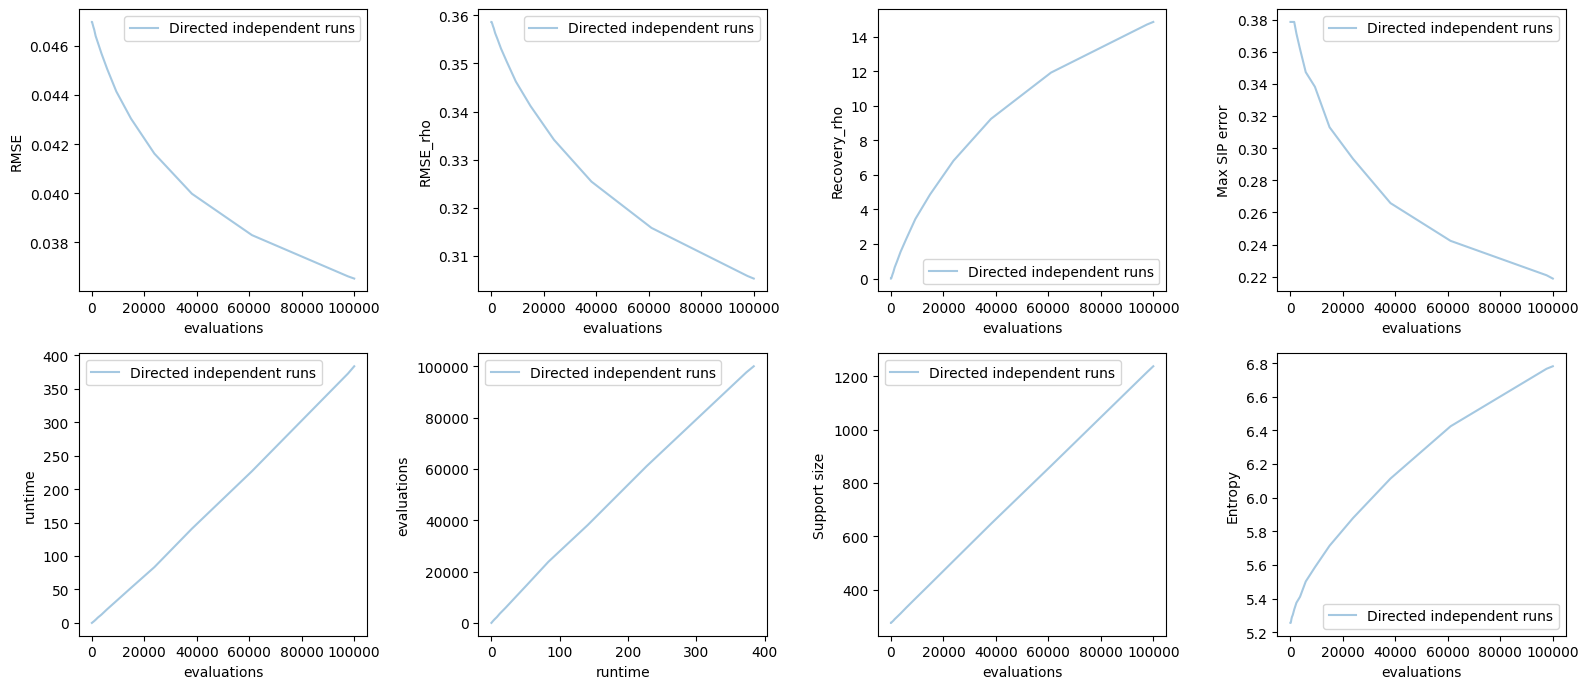

In [20]:
directed_result = None  # First run retained for compatibility; comparisons use ALL runs.
directed_results = []
directed_runs = pd.DataFrame()
directed_statistics = pd.DataFrame()
directed_convergence = pd.DataFrame()
directed_folder = None
if RUN_GFS_DIRECTED:
    import os
    from joblib import Parallel, delayed, parallel_config
    from prescribed_sip.methods.notebook_directed import directed_repetition

    def run_directed(evaluations, seed):
        return directed_repetition(0, seed, extract_support(p0), Pi_star, pi,
                                  evaluations, DIRECTED_BATCH_SIZE,
                                  float("inf") if ALLOW_LONG_RUN else 1800., RHO_BOUNDARY_TOL, DIRECTED_RMSE_STOP)[2]

    for name, value in [("N_REPETITIONS", N_REPETITIONS), ("DIRECTED_N_JOBS", DIRECTED_N_JOBS),
                        ("DIRECTED_MAX_EVALUATIONS", DIRECTED_MAX_EVALUATIONS),
                        ("DIRECTED_BATCH_SIZE", DIRECTED_BATCH_SIZE)]:
        if isinstance(value, bool) or not isinstance(value, (int, np.integer)) or value < 1:
            raise ValueError(f"{name} must be a positive integer.")
    available_cpus = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else (os.cpu_count() or 1)
    directed_workers = min(DIRECTED_N_JOBS, N_REPETITIONS, available_cpus)
    # Independent reproducible random streams; pilot has a separate seed.
    directed_seeds = [int(s.generate_state(1)[0])
                      for s in np.random.SeedSequence(SEED + 4).spawn(N_REPETITIONS)]
    run_directed_full = True
    if N >= 100:
        directed_pilot = run_directed(min(BENCHMARK_EVALUATIONS, DIRECTED_MAX_EVALUATIONS), SEED + 5)
        if directed_pilot.status == "numerical_failure":
            raise RuntimeError(directed_pilot.failure_reason)
        directed_speed = directed_pilot.runtime_seconds / max(directed_pilot.candidate_moves, 1)
        directed_waves = (N_REPETITIONS + directed_workers - 1) // directed_workers
        directed_estimate = 3 * directed_speed * DIRECTED_MAX_EVALUATIONS * directed_waves
        print(f"Directed pilot: {1000 * directed_speed:.2f} s / 1000 evaluations; "
              f"protected total wall-time estimate ({directed_workers} workers, {directed_waves} waves): "
              f"{directed_estimate / 60:.2f} min; parallel contention may increase it.")
        run_directed_full = runtime_permitted(directed_estimate, ALLOW_LONG_RUN)
    if run_directed_full:
        if DIRECTED_SAVE_RESULTS:
            from datetime import datetime, timezone
            stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
            directed_folder = REPO / "prescribed_sip/results/notebook_directed" / f"N{N}_n{n}_{stamp}"
            directed_folder.mkdir(parents=True, exist_ok=False)
            np.savez(directed_folder / "frozen_problem.npz", pi=pi, x=x, Pi0=Pi0, Pi_star=Pi_star,
                     target_permutation=target_permutation, Pi_target_initial=Pi_target_initial)
            import json
            (directed_folder / "settings.json").write_text(json.dumps({
                "N": N, "n": n, "sampling_fraction": n / N, "POPULATION": POPULATION,
                "FIP_TYPE": FIP_TYPE, "SEED": SEED, "TARGET_ATTEMPTS": TARGET_ATTEMPTS,
                "TARGET_ALPHA": TARGET_ALPHA, "TARGET_M": TARGET_M,
                "target_permutation": target_permutation.tolist(),
                "reconstruction_order": "original unit-ID order",
                "N_REPETITIONS": N_REPETITIONS,
                "DIRECTED_MAX_EVALUATIONS": DIRECTED_MAX_EVALUATIONS,
                "DIRECTED_RMSE_STOP": DIRECTED_RMSE_STOP,
                "DIRECTED_BATCH_SIZE": DIRECTED_BATCH_SIZE, "DIRECTED_N_JOBS": DIRECTED_N_JOBS,
                "actual_workers": directed_workers,
                "seconds_per_run": None if ALLOW_LONG_RUN else 1800,
                "rho_boundary_tol": RHO_BOUNDARY_TOL, **rho_profile.counts(), "seeds": directed_seeds,
                "initial_support": [[list(s), p] for s, p in distribution(p0).items()],
            }, indent=2) + "\n")
            print("Directed results saved after each repetition to:", directed_folder)
        print(f"Starting {N_REPETITIONS} independent GFS-Directed runs; "
              f"<= {DIRECTED_MAX_EVALUATIONS:,} scored directions EACH; "
              f"batch={DIRECTED_BATCH_SIZE}; workers={directed_workers}; "
              f"early stop: raw RMSE < {DIRECTED_RMSE_STOP:g}; fixed p0 and Pi_star.", flush=True)
        rows, histories, outcomes = [], {}, {}
        directed_wall_started = perf_counter()
        initial_support = extract_support(p0)
        seconds_per_run = float("inf") if ALLOW_LONG_RUN else 1800.
        # loky workers are safe in Jupyter; worker function lives in an importable module.
        with parallel_config(backend="loky", inner_max_num_threads=1):
            if directed_workers == 1:
                finished_runs = (directed_repetition(j, seed, initial_support, Pi_star, pi,
                                    DIRECTED_MAX_EVALUATIONS, DIRECTED_BATCH_SIZE, seconds_per_run, RHO_BOUNDARY_TOL, DIRECTED_RMSE_STOP)
                                 for j, seed in enumerate(directed_seeds, start=1))
            else:
                finished_runs = Parallel(n_jobs=directed_workers, return_as="generator_unordered",
                                         batch_size=1, pre_dispatch=directed_workers)(
                    delayed(directed_repetition)(j, seed, initial_support, Pi_star, pi,
                        DIRECTED_MAX_EVALUATIONS, DIRECTED_BATCH_SIZE, seconds_per_run, RHO_BOUNDARY_TOL, DIRECTED_RMSE_STOP)
                    for j, seed in enumerate(directed_seeds, start=1))
            for repetition, seed, result in finished_runs:
                if result.status == "numerical_failure":
                    raise RuntimeError(f"Directed repetition {repetition}: {result.failure_reason}")
                checks = validate_design(result.support, pi)
                # Final errors are independently recomputed from the actual sampling distribution.
                final_Pi = compute_SIP(result.support)
                metrics = sip_errors(final_Pi, Pi_star)
                row = {"repetition": repetition, "seed": seed, "Worker PID": result.details["worker_pid"],
                       "RMSE": metrics["RMSE"],
                       **comparison_metrics(final_Pi),
                       "Recovery %": recovery_percent(metrics["RMSE"]),
                       "Max SIP error": metrics["Max SIP error"],
                       "Runtime": result.runtime_seconds, "Evaluations": result.candidate_moves,
                       "Budget reached": result.candidate_moves == DIRECTED_MAX_EVALUATIONS,
                       "Status": result.status, "Stop reason": result.failure_reason,
                       "FIP max error": checks["FIP max error"],
                       "SIP incremental error": result.validation["max_SIP_incremental_error"],
                       "Support size": len(distribution(result.support)), "Entropy": entropy(result.support)}
                rows.append(row)
                outcomes[repetition] = result
                directed_results = [outcomes[j] for j in sorted(outcomes)]
                history = pd.DataFrame(result.checkpoints)
                history["repetition"], history["seed"] = repetition, seed
                history["evaluations"] = history["candidate_moves"]
                history["runtime"] = history["runtime_seconds"]
                history["D2"] = history["incumbent_D2"]
                history["RMSE"] = history["incumbent_target_RMSE2"]
                history["Recovery %"] = history["RMSE"].map(recovery_percent)
                history["RMSE_rho"] = history["incumbent_RMSE_rho"]
                history["Recovery_rho"] = history["incumbent_Recovery_rho"]
                history["Max SIP error"] = history["incumbent_Dinf"]
                history["Support size"] = history["incumbent_support_size"]
                history["Entropy"] = history["incumbent_entropy"]
                histories[repetition] = history
                directed_runs = pd.DataFrame(rows).sort_values("repetition").reset_index(drop=True)
                directed_convergence = pd.concat([histories[j] for j in sorted(histories)], ignore_index=True)
                statistic_columns = ["RMSE", "RMSE_rho", "Recovery_rho", "Recovery %", "Runtime", "Evaluations",
                                     "Max SIP error", "FIP max error", "Support size", "Entropy"]
                directed_statistics = directed_runs[statistic_columns].agg(["mean", "std"]).T
                directed_statistics.columns = ["Mean", "SD"]  # Sample SD, ddof=1; NA for one run.
                if directed_folder is not None:
                    directed_runs.to_csv(directed_folder / "directed_runs.csv", index=False)
                    directed_convergence.to_csv(directed_folder / "directed_convergence.csv", index=False)
                    directed_statistics.to_csv(directed_folder / "directed_statistics.csv", index_label="Metric")
                    # Preserve final designs so dependence metrics can be independently audited later.
                    (directed_folder / "directed_supports.json").write_text(json.dumps([
                        {"repetition": j, "samples": [[list(s), p] for s, p in outcomes[j].support.mass.items()]}
                        for j in sorted(outcomes)], indent=2) + "\n")
                print(f"Directed {len(rows)}/{N_REPETITIONS} completed (run {repetition}): RMSE={row['RMSE']:.6g}; "
                      f"RMSE_rho={row['RMSE_rho']:.6g}; Recovery_rho={row['Recovery_rho']:.2f}%; "
                      f"{row['Evaluations']:,}/{DIRECTED_MAX_EVALUATIONS:,} evaluations; "
                      f"{row['Runtime']:.2f} s; {row['Status']} / {row['Stop reason'] or 'budget loop finished'}; "
                      f"{N_REPETITIONS - len(rows)} repetitions remaining.", flush=True)
        directed_result = directed_results[0]  # Run 1, regardless of completion order.
        directed_wall_seconds = perf_counter() - directed_wall_started
        print(f"All Directed repetitions finished in {directed_wall_seconds:.2f} s wall time; "
              f"{directed_workers} worker processes; per-run runtimes remain in directed_runs.")
        print(f"Directed mean ± sample SD over {len(directed_runs)} independent runs:")
        for metric in ["RMSE", "RMSE_rho", "Recovery_rho"]:
            print(f"  {metric}: {directed_statistics.loc[metric, 'Mean']:.6g} ± "
                  f"{directed_statistics.loc[metric, 'SD']:.6g}")
        print(f"Reached full evaluation cap: {int(directed_runs['Budget reached'].sum())}/{N_REPETITIONS}; "
              "all valid final results are included, including earlier stops.")
        fig, axes = plt.subplots(2, 4, figsize=(16, 7))
        for ax, y_column in zip(axes.flat, ["RMSE", "RMSE_rho", "Recovery_rho", "Max SIP error",
                                          "runtime", "evaluations", "Support size", "Entropy"]):
            x_column = "runtime" if y_column == "evaluations" else "evaluations"
            if gfs_result is not None:
                history = gfs_result["trace"]
                ax.plot(history[x_column], history[y_column], label=gfs_result["method"], color="C1")
            for repetition, history in directed_convergence.groupby("repetition"):
                ax.plot(history[x_column], history[y_column], color="C0", alpha=.4,
                        label="Directed independent runs" if repetition == 1 else None)
            ax.set_xlabel(x_column); ax.set_ylabel(y_column); ax.legend()
        plt.tight_layout(); plt.show()
    else:
        print("*** LONG DIRECTED REPETITIONS BLOCKED *** Set ALLOW_LONG_RUN=True "
              "to opt into the estimated total duration above 30 minutes.")
else:
    print("GFS-Directed skipped by USER SETTINGS.")


## 11. Optional CP(2): existing enumerated implementation

The repository implementation fits the fixed-size exponential family
$p(s)\propto\exp(\sum_i a_iI_i(s)+\sum_{i<j}b_{ij}I_i(s)I_j(s))$ using an exact
partition function, a dual L-BFGS fit, and a final Newton FIP tilt. For $n>1$,
first-order terms can be absorbed into pair terms. This is **enumerated CP(2)
calibration**, not a reproduction of Bondesson's iterative/Gibbs program.

Enumeration is disabled at `N >= 100` or when the sample count exceeds the settings
limit. Competitors receive `pi` and `Pi_star`, not target sample probabilities.

In [21]:
method_results = []

def summary_row(method, design, runtime=0., evaluations=0, Pi=None):
    computed_Pi = compute_SIP(design) if Pi is None else Pi
    metrics = sip_errors(computed_Pi, Pi_star)
    checks = validate_design(design, pi)
    return {"Method": method, "RMSE": metrics["RMSE"],
            **comparison_metrics(computed_Pi), "Repetitions": 1,
            "RMSE SD": np.nan, "RMSE_rho SD": np.nan, "Recovery_rho SD": np.nan,
            "Recovery %": recovery_percent(metrics["RMSE"]),
            "Max SIP error": metrics["Max SIP error"], "Runtime": runtime,
            "Evaluations": evaluations, "FIP max error": checks["FIP max error"],
            "Support size": len(distribution(design)), "Entropy": entropy(design)}

method_results.append(summary_row("Initial", p0))
if gfs_result is not None:
    method_results.append(summary_row(gfs_result["method"], gfs_result["design"],
                          gfs_result["runtime"], gfs_result["evaluations"]))

if not directed_runs.empty:
    # Numerical columns are MEANS across runs; design invariants checked for EVERY run.
    means = directed_statistics["Mean"]
    method_results.append({"Method": "GFS-Directed", "Repetitions": len(directed_runs),
        **rho_profile.counts(),
        **{column: means[column] for column in directed_statistics.index},
        **{column + " SD": directed_statistics.loc[column, "SD"]
           for column in ["RMSE", "RMSE_rho", "Recovery_rho"]}})
    print("Directed row reports run means; maximum FIP error over ALL runs:",
          directed_runs["FIP max error"].max())

can_enumerate = enumeration_allowed(N, n)
print(f"Possible fixed-size samples: C({N},{n}) = {comb(N, n):,}")
if not can_enumerate:
    print("Enumerated CP(2) and exact LP/QP automatically disabled: "
          "N >= 100 or sample count exceeds ENUMERATION_LIMIT. No enumeration allocated.")
if RUN_CP2 and can_enumerate:
    from prescribed_sip.methods.cp2 import fit_cp2
    from prescribed_sip.core.objective import PairObjective
    cp2 = fit_cp2(N, n, pi, PairObjective(N, Pi_star),
                  evaluations=CP2_MAX_EVALUATIONS, seconds=CP2_MAX_SECONDS,
                  initial=extract_support(p0))
    print("CP(2) status:", cp2.status, cp2.failure_reason)
    print("Calibration details:", cp2.details)
    method_results.append(summary_row("CP(2) — enumerated fit", cp2.support,
                          cp2.runtime_seconds, cp2.candidate_moves))
else:
    print("CP(2) skipped (setting or enumeration safeguard).")


Directed row reports run means; maximum FIP error over ALL runs: 2.4424906541753444e-14
Possible fixed-size samples: C(281,40) = 5,892,065,289,004,034,574,919,903,566,604,031,473,739,370,190,200
Enumerated CP(2) and exact LP/QP automatically disabled: N >= 100 or sample count exceeds ENUMERATION_LIMIT. No enumeration allocated.
CP(2) skipped (setting or enumeration safeguard).


## 12. Optional DSD: restricted projection/order fitting

For a projection factor $V$ with $V^TV=I_n$ and
$\sum_k V_{ik}^2=\pi_i$, set $K=VV^T$. Its SIP are
$\pi_{ij}=\pi_i\pi_j-K_{ij}^2$ for $i\ne j$; set the diagonal to $\pi_i$.
We use the repository's validated projection construction, then try random
permutations of its input order, map rows back to the original units, and retain
the closest observed SIP under the same D2 loss. This finite fit searches only
this order-dependent family; it is **not a global DSD optimum**.

Projection DSD always has $\pi_{ij}\le\pi_i\pi_j$. Positive pair covariance in the
target makes exact projection-DSD recovery impossible. At small sizes we also
validate moments from sample probabilities $p(s)=\det(V_s)^2$. At large sizes,
SIP and FIP are analytic; support size and entropy are not enumerated or reported.

In [22]:
if RUN_DSD:
    from prescribed_sip.methods.dsd import projection_factor
    dsd_started = perf_counter()
    dsd_rng = np.random.default_rng(SEED + 3)
    dsd_best_loss, dsd_best_Pi, dsd_best_V = np.inf, None, None
    for evaluation in range(DSD_MAX_EVALUATIONS):
        permutation = np.arange(N) if evaluation == 0 else dsd_rng.permutation(N)
        V_ordered = projection_factor(pi[permutation])
        V = np.zeros_like(V_ordered)
        V[permutation] = V_ordered
        K = V @ V.T
        Pi_dsd = np.outer(pi, pi) - K ** 2
        np.fill_diagonal(Pi_dsd, pi)
        loss = sip_errors(Pi_dsd, Pi_star)["D2"]
        if loss < dsd_best_loss:
            dsd_best_loss, dsd_best_Pi, dsd_best_V = loss, Pi_dsd, V
    if dsd_best_V is None:
        raise ValueError("DSD_MAX_EVALUATIONS must be positive.")
    dsd_fip_error = float(np.max(abs(np.sum(dsd_best_V ** 2, axis=1) - pi)))
    orthogonality_error = float(np.max(abs(dsd_best_V.T @ dsd_best_V - np.eye(n))))
    if max(dsd_fip_error, orthogonality_error) > 1e-10:
        raise ValueError("DSD projection/FIP validation failed.")
    if can_enumerate:
        from prescribed_sip.core.design import Support
        dsd_mass = {sample: float(np.linalg.det(dsd_best_V[list(sample)]) ** 2)
                    for sample in combinations(range(N), n)}
        dsd_support = Support(N, n, {s: p for s, p in dsd_mass.items() if p > 0})
        discrepancies = float(np.max(abs(compute_SIP(dsd_support) - dsd_best_Pi)))
        if discrepancies > 1e-10:
            raise ValueError("Analytic DSD SIP disagree with enumerated probabilities.")
        dsd_row = summary_row("DSD — projection/order fit", dsd_support,
                             perf_counter() - dsd_started, DSD_MAX_EVALUATIONS)
        print("DSD support-to-analytic SIP discrepancy:", discrepancies)
    else:
        dsd_metrics = sip_errors(dsd_best_Pi, Pi_star)
        dsd_row = {"Method": "DSD — projection/order fit", "RMSE": dsd_metrics["RMSE"],
                   **comparison_metrics(dsd_best_Pi), "Repetitions": 1,
                   "RMSE SD": np.nan, "RMSE_rho SD": np.nan, "Recovery_rho SD": np.nan,
                   "Recovery %": recovery_percent(dsd_metrics["RMSE"]),
                   "Max SIP error": dsd_metrics["Max SIP error"],
                   "Runtime": perf_counter() - dsd_started,
                   "Evaluations": DSD_MAX_EVALUATIONS, "FIP max error": dsd_fip_error,
                   "Support size": np.nan, "Entropy": np.nan}
    method_results.append(dsd_row)
    positive_covariances = ((Pi_star - np.outer(pi, pi))[pair_indices] > 1e-12).sum()
    print(f"DSD: closest observed RMSE={dsd_row['RMSE']:.10g}; "
          f"RMSE_rho={dsd_row['RMSE_rho']:.10g}; Recovery_rho={dsd_row['Recovery_rho']:.2f}%; "
          f"target positive-covariance pairs={positive_covariances}")
else:
    print("DSD skipped by USER SETTINGS.")


DSD skipped by USER SETTINGS.


## 13. Optional exact enumerated LP/QP oracle

The existing oracle enumerates fixed-size samples, imposes nonnegative probabilities,
unit total probability, prescribed FIP, and the target pair moments. It first solves
linear SIP feasibility. A feasible solution already gives numerical zero error and
proves the minimum D2 is zero to solver precision; QP is unnecessary then. If the LP
reports infeasibility, the implementation solves a convex squared-error QP and
reports its certificate. This is a small-population oracle, not a scalable sampler.

In [23]:
if RUN_EXACT_QP and can_enumerate:
    from prescribed_sip.methods.exact import exact_benchmark
    from prescribed_sip.core.objective import PairObjective
    exact = exact_benchmark(N, n, pi, PairObjective(N, Pi_star),
                            seconds=EXACT_MAX_SECONDS)
    print("Exact oracle:", {k: v for k, v in exact.items() if k != "support"})
    if exact["support"] is not None:
        method_results.append(summary_row("Exact LP/QP oracle", exact["support"],
                              exact["runtime_seconds"], 0))
    else:
        print("No validated oracle design returned; inspect solver status above.")
else:
    print("Exact LP/QP skipped (setting or enumeration safeguard).")


Exact LP/QP skipped (setting or enumeration safeguard).


## 14. Final comparison and what to try next

All methods use the same prescribed FIP and frozen target SIP. `Evaluations` means
scored candidate designs for GFS, dual evaluations for CP(2), and scored kernels for
DSD; these counts are **not interchangeable**. The oracle count is zero because no
GFS candidates are scored. Runtimes are serial measurements in this notebook.

Change one setting at a time and restart the kernel: exchange count changes the
scientific target, whereas reconstruction budget changes how long GFS searches for
that fixed target. Increase the latter to inspect whether the error continues to
fall. One successful or unsuccessful run is not a general convergence guarantee.
The notebook does not automatically write over any completed study results.

In [24]:
summary = pd.DataFrame(method_results).drop(columns=["Recovery %"], errors="ignore")
# Format the display only; summary retains the full-precision numeric values.
error_format = lambda value: f"{value:.2e}" if 0 < abs(value) < 0.01 else f"{value:.2f}"
table_formats = {column: error_format for column in ["RMSE", "RMSE SD", "RMSE_rho", "RMSE_rho SD", "Max SIP error", "FIP max error"]}
table_formats.update({column: "{:.2f}" for column in ["Recovery_rho", "Recovery_rho SD", "Runtime", "Entropy", "Evaluations", "Support size"]})
print("Directed values are means over Repetitions; SD is sample SD. Other methods have one fit (SD=NA).")
display(summary.style.format(table_formats, na_rep="NA").hide(axis="index"))
print(f"Target created after {attempted_exchanges:,} attempted random package GFS exchanges; "
      f"{accepted_exchanges:,} changed the distribution.")
print(f"Initial-to-target RMSE = {baseline_rmse:.10g}; RMSE_rho = {baseline_rho_error:.10g}")
if gfs_result is not None:
    print(f"{gfs_result['method']} after {gfs_result['evaluations']:,} scored candidates: "
          f"RMSE={gfs_result['RMSE']:.10g}, RMSE_rho={gfs_result['RMSE_rho']:.10g}, "
          f"Recovery_rho={gfs_result['Recovery_rho']:.2f}%.")
for row in method_results:
    if row["Method"] not in {"Initial", "Original GFS", "Original GFS + restarts"}:
        print(f"{row['Method']}: RMSE={row['RMSE']:.10g}; RMSE_rho={row['RMSE_rho']:.10g}; "
              f"Recovery_rho={row['Recovery_rho']:.2f}%; Repetitions={row['Repetitions']}")
print(f"Rho pairs excluded: {rho_profile.excluded}/{number_of_pairs}; included: {rho_profile.included}.")
if directed_folder is not None:
    summary.to_csv(directed_folder / "summary.csv", index=False)
    target_history.to_csv(directed_folder / "target_history.csv", index=False)
    if gfs_result is not None:
        gfs_result["trace"].to_csv(directed_folder / "gfs_convergence.csv", index=False)
print("All returned supports independently checked; large DSD uses analytic kernel checks.")


Directed values are means over Repetitions; SD is sample SD. Other methods have one fit (SD=NA).


Method,RMSE,RMSE_rho,Recovery_rho,Rho pairs included,Rho pairs excluded,Repetitions,RMSE SD,RMSE_rho SD,Recovery_rho SD,Max SIP error,Runtime,Evaluations,FIP max error,Support size,Entropy
Initial,0.05,0.36,0.00,39340,0,1,NA,NA,NA,0.38,0.00,0.00,2.12e-14,276.00,5.25
GFS-Directed,0.04,0.31,14.86,39340,0,1,NA,NA,NA,0.22,383.81,100000.00,2.44e-14,1237.00,6.78


Target created after 10,000 attempted random package GFS exchanges; 9,995 changed the distribution.
Initial-to-target RMSE = 0.04697940202; RMSE_rho = 0.3586273451
GFS-Directed: RMSE=0.03652754596; RMSE_rho=0.3053251278; Recovery_rho=14.86%; Repetitions=1
Rho pairs excluded: 0/39340; included: 39340.
All returned supports independently checked; large DSD uses analytic kernel checks.


### Optional: save this demonstration separately

Uncomment only if you want local files. The folder is separate from the frozen
paper experiment. The notebook already retains `target_history`, `convergence`
(if GFS ran), `summary`, `p0`, `p_star`, and the SIP matrices for personal inspection.

In [25]:
# demo_folder = REPO / "prescribed_sip/results/notebook_demo"
# demo_folder.mkdir(parents=True, exist_ok=True)
# summary.to_csv(demo_folder / "summary.csv", index=False)
# target_history.to_csv(demo_folder / "target_history.csv", index=False)
# np.savez(demo_folder / "moments.npz", pi=pi, x=x, Pi0=Pi0, Pi_star=Pi_star, target_permutation=target_permutation)
# if gfs_result is not None:
#     gfs_result["trace"].to_csv(demo_folder / "gfs_convergence.csv", index=False)

# if directed_result is not None:
#     directed_convergence.to_csv(demo_folder / "directed_convergence.csv", index=False)

# Directed per-run files are already saved automatically when DIRECTED_SAVE_RESULTS=True.
# if not directed_runs.empty:
#     directed_runs.to_csv(demo_folder / "directed_runs.csv", index=False)
#     directed_statistics.to_csv(demo_folder / "directed_statistics.csv", index_label="Metric")
